In [68]:
%pip install pandas numpy matplotlib seaborn scipy scikit-learn xgboost --quiet

Note: you may need to restart the kernel to use updated packages.


This project measures how effective each instructor is using 2,000 course batches from 120 instructors.

It uses seven metrics like completion rate, quiz score, and student feedback to judge teaching quality.

A single score called IES (Instructor Effectiveness Score) is built using PCA weights, ranging from 0 to 1.

Instructors are grouped into three tiers — Low, Medium, and High — based on their IES.

Batch-level data is averaged up to the instructor level, giving one clean row per instructor.

Four machine learning models are trained to predict the tier, and Logistic Regression wins with 97% accuracy.

The results show that completion rate, quiz score, and feedback score are the strongest signs of a good instructor.



## Importing libraries

In [ ]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from scipy import stats
from itertools import combinations
from sklearn.decomposition import PCA 
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score 
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier

## Loading Data

In [3]:
df = pd.read_csv("instructor_effectiveness_dataset_2000_rows - instructor_effectiveness_dataset_2000_rows.csv")
df = df.set_index('batch_id')   

In [4]:
df.head()

,instructor_id,course_id,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
batch_id,,,,,,,,,,,
B_1861,I_044,C_01,0.300000,14.225955,73.546528,0.647423,0.774572,0.790918,0.108414,3.766211,0.533193
B_0354,I_119,C_06,0.657220,22.871110,77.312331,0.425098,0.494936,0.998566,0.280550,5.000000,0.734087
B_1334,I_050,C_03,0.300000,16.087517,79.563687,0.700000,0.977901,0.807298,0.207013,3.517386,0.681433
B_0906,I_024,C_21,0.639507,24.260687,99.295316,0.334657,0.846515,0.544555,0.306395,4.207578,1.000000
B_1290,I_001,C_08,0.527302,31.081556,99.393425,0.521099,0.917450,0.865885,0.252289,4.426230,0.696710


## Step 1 - EDA

Index 

| # | Content Summary |
|---|---|
| 1 | `%pip install pandas numpy matplotlib seaborn scipy scikit-learn xgboost --quiet` |
| 2 | Imports: pandas, numpy, matplotlib, seaborn, scipy, sklearn, xgboost |
| 3 | Loads CSV → `df`, sets `batch_id` as index |
| 4 | `df.head()` — preview |
| 5 | `df.info()` — dtypes + null check |
| 6 | `df.describe()` — summary stats |
| 7 | `df.duplicated().sum()` |
| 8 | `df.columns` |
| 9 | `completion_rate` describe |
| 10 | `dropout_rate` describe |
| 11 | `assignment_submission_rate` describe |
| 12 | `forum_activity_rate` describe |
| 13 | `feedback_response_rate` describe |
| 14 | `avg_quiz_score` describe |
| 15 | `avg_feedback_score` describe |
| 16 | `avg_score_improvement` describe |
| 17 | Defines `numerical_cols`, `categorical_cols` |
| 18 | Summary stats table `stats_` (skew, kurtosis, CV) |
| 19 | Histograms (3×3) for numeric columns |
| 20 | Box plots (3×3) |
| 21 | Bar plots (1×3) for categorical |
| 22 | `instructor_id` describe |
| 23 | `course_id` describe |
| 24 | Correlation heatmap |
| 25 | Correlations with targets |
| 26 | Defines `get_pairs()`, `pairs` |
| 27 | `classify_pair()` + `pair_df` |
| 28 | Defines 3 analysis functions (num-num, num-cat, cat-cat) |
| 29 | Runs pairwise analyses → `results_df` |
| 30 | Shows `num-num` results |
| 31 | Shows `num-cat` results |
| 32 | Shows `cat-cat` results |
| 33 | Prints top num-num / num-cat / cat-cat relationships |
| 34 | IQR outlier detection → `outlier_df` |

**Functions defined:** `get_pairs`, `classify_pair`, `analyze_numerical_numerical`, `analyze_numerical_categorical`, `analyze_categorical_categorical`, `detect_outliers_iqr`

**DataFrames created:** `df`, `stats_`, `pair_df`, `results_df`, `num_num`, `num_cat`, `cat_cat`, `outlier_df`

**Plots:** Histograms (3×3), Box plots (3×3), Bar plots (1×3), Correlation heatmap

In [5]:
df.info()
# There are no null values

<class 'pandas.core.frame.DataFrame'>
Index: 2000 entries, B_1861 to B_1127
Data columns (total 11 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   instructor_id               2000 non-null   object 
 1   course_id                   2000 non-null   object 
 2   completion_rate             2000 non-null   float64
 3   avg_score_improvement       2000 non-null   float64
 4   avg_quiz_score              2000 non-null   float64
 5   dropout_rate                2000 non-null   float64
 6   avg_watch_time              2000 non-null   float64
 7   assignment_submission_rate  2000 non-null   float64
 8   forum_activity_rate         2000 non-null   float64
 9   avg_feedback_score          2000 non-null   float64
 10  feedback_response_rate      2000 non-null   float64
dtypes: float64(9), object(2)
memory usage: 187.5+ KB


In [6]:
df.describe()

,completion_rate,avg_score_improvement,avg_quiz_score,dropout_rate,avg_watch_time,assignment_submission_rate,forum_activity_rate,avg_feedback_score,feedback_response_rate
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.602808,27.035844,77.956126,0.394883,0.776515,0.753188,0.250300,4.207134,0.736519
std,0.159667,5.716641,10.695618,0.162747,0.145231,0.148058,0.100640,0.419209,0.149412
min,0.300000,6.159240,40.386725,0.020000,0.287440,0.251111,0.000000,2.639915,0.259935
25%,0.489260,23.124673,70.897590,0.280035,0.675076,0.652110,0.179845,3.918986,0.633293
50%,0.603091,26.938629,78.020567,0.394820,0.780330,0.756380,0.249771,4.205989,0.737213
75%,0.712797,30.885600,85.444286,0.511432,0.894242,0.856458,0.319204,4.503437,0.845876
max,0.980000,40.000000,100.000000,0.700000,1.000000,1.000000,0.641111,5.000000,1.000000


In [7]:
df.duplicated().sum()
# There are no duplicates 

0

In [8]:
df.columns

Index(['instructor_id', 'course_id', 'completion_rate',
       'avg_score_improvement', 'avg_quiz_score', 'dropout_rate',
       'avg_watch_time', 'assignment_submission_rate', 'forum_activity_rate',
       'avg_feedback_score', 'feedback_response_rate'],
      dtype='object')

Check if all the rates are between 0 and 1

In [9]:
df['completion_rate'].describe()
# Values are between 0 and 1

count    2000.000000
mean        0.602808
std         0.159667
min         0.300000
25%         0.489260
50%         0.603091
75%         0.712797
max         0.980000
Name: completion_rate, dtype: float64

In [10]:
df['dropout_rate'].describe()
# Values are between 0 and 1

count    2000.000000
mean        0.394883
std         0.162747
min         0.020000
25%         0.280035
50%         0.394820
75%         0.511432
max         0.700000
Name: dropout_rate, dtype: float64

In [11]:
df['assignment_submission_rate'].describe()
# Values are between 0 and 1

count    2000.000000
mean        0.753188
std         0.148058
min         0.251111
25%         0.652110
50%         0.756380
75%         0.856458
max         1.000000
Name: assignment_submission_rate, dtype: float64

In [12]:
df['forum_activity_rate'].describe()
# Values are between 0 and 0.641

count    2000.000000
mean        0.250300
std         0.100640
min         0.000000
25%         0.179845
50%         0.249771
75%         0.319204
max         0.641111
Name: forum_activity_rate, dtype: float64

In [13]:
df['feedback_response_rate'].describe()
# Values are between 0 and 1

count    2000.000000
mean        0.736519
std         0.149412
min         0.259935
25%         0.633293
50%         0.737213
75%         0.845876
max         1.000000
Name: feedback_response_rate, dtype: float64

Check if score is between 0 and 1

In [14]:
df['avg_quiz_score'].describe()
# Values are between 40 and 100

count    2000.000000
mean       77.956126
std        10.695618
min        40.386725
25%        70.897590
50%        78.020567
75%        85.444286
max       100.000000
Name: avg_quiz_score, dtype: float64

In [15]:
df['avg_feedback_score'].describe()
# Values are between 2 to 5

count    2000.000000
mean        4.207134
std         0.419209
min         2.639915
25%         3.918986
50%         4.205989
75%         4.503437
max         5.000000
Name: avg_feedback_score, dtype: float64

In [16]:
df['avg_score_improvement'].describe()
# Values are between 6 to 40

count    2000.000000
mean       27.035844
std         5.716641
min         6.159240
25%        23.124673
50%        26.938629
75%        30.885600
max        40.000000
Name: avg_score_improvement, dtype: float64

In [17]:
numerical_cols = [
    'completion_rate', 'avg_score_improvement', 'avg_quiz_score',
    'dropout_rate', 'avg_watch_time', 'assignment_submission_rate',
    'forum_activity_rate', 'avg_feedback_score', 'feedback_response_rate'
]

categorical_cols = ['instructor_id', 'course_id']

In [18]:
# Summary statistics
stats_ = df[numerical_cols].describe().T
stats_['range'] = stats_['max'] - stats_['min']
stats_['coeff_of_var'] = stats_['std'] / stats_['mean']  
stats_['skew'] = df[numerical_cols].skew()
stats_['kurtosis'] = df[numerical_cols].kurtosis()

print(stats_.round(3))

                             count    mean     std     min     25%     50%  \
completion_rate             2000.0   0.603   0.160   0.300   0.489   0.603   
avg_score_improvement       2000.0  27.036   5.717   6.159  23.125  26.939   
avg_quiz_score              2000.0  77.956  10.696  40.387  70.898  78.021   
dropout_rate                2000.0   0.395   0.163   0.020   0.280   0.395   
avg_watch_time              2000.0   0.777   0.145   0.287   0.675   0.780   
assignment_submission_rate  2000.0   0.753   0.148   0.251   0.652   0.756   
forum_activity_rate         2000.0   0.250   0.101   0.000   0.180   0.250   
avg_feedback_score          2000.0   4.207   0.419   2.640   3.919   4.206   
feedback_response_rate      2000.0   0.737   0.149   0.260   0.633   0.737   

                               75%      max   range  coeff_of_var   skew  \
completion_rate              0.713    0.980   0.680         0.265  0.109   
avg_score_improvement       30.886   40.000  33.841         0.211 -

- Central Tendency (mean and median 50%): The mean and median are almost identical for every variable. This is a strong indicator of symmetric distribution. Any instructor or course whose metrics deviate significantly from these benchmarks is either outperforming or underperforming.
- Spread (std, coeff_of_var):
    - `avg_feedback_score` (0.419, 0.100): Lowest
    - `avg_quiz_score` (10.70, 0.137): Very Low
    - `avg_watch_time` (0.145, 0.0.187): Low
    - `assignment_submission_rate` (0.148, 0.197): Low
    - `avg_score_improvement` (5.72, 0.211): Low
    - `feedback_response_rate` (0.149, 0.203): Low
    - `completion_rate` (0.160, 0.265): Moderate
    - `dropout_rate` (0.163, 0.412): High
    - `forum_activity_rate` (0.101, 0.402): High
    
    The most important features are `forum_activity_rate`, `dropout_rate`, `completion_rate`, `avg_score_improvement`.
- Skewness 
    - `completion_rate`: +0.109 Symmetric
    - `avg_score_improvement`: - 0.003: Perfectly symmetric
    - `avg_quiz_score`: -0.200: Slightly left-skewed
    - `dropout_rate`: -0.103: Symmetric
    - `avg_watch_time`: -0.318: Left-skewed
    - `assignmnet_submission_rate`: -0.256 Slightly left-skewed
    - `forum_activity_rate`: +0.045 Symmetric
    - `avg_feedback_score`: -0.172 Slightly left skewed
    - `feedback_response_rate`: -0.175: Slightly left-skewed
    
    All skewness values are within [-0.5,+0.5] - the dataset is symmetric. No log transformations are needed for any variable before regression.
- Kurtosis - Tail Behavior
    Excess kurtosis (normal = 0):
    Negative -> platykurtic (flatter, thinner tails, fewer outliers)
    Positive -> leptokurtic (peaked, fat tails, more outliers)
    - `completion_rate`: -0.450 Flat 
    - `avg_score_improvement`: -0.166 Nearly normal tails
    - `avg_quiz_score`: -0.066 Almost perfectly normal tails
    - `dropout_rate`: -0.569 Flat 
    - `avg_watch_time`: -0.493 Flat
    - `assignmnet_submission_rate`: -0.374 Flat
    - `forum_activity_rate`: -0.101 Nearly normal
    - `avg_feedback_score`: -0.299 Flat
    - `feedback_response_rate`: -0.438 Flat

    All kurtosis values are negative. This means fewer extreme outliers. avg_quiz_score has kurtosis nearly equal to 0 -> nearly a perfect bell curve.

Plots

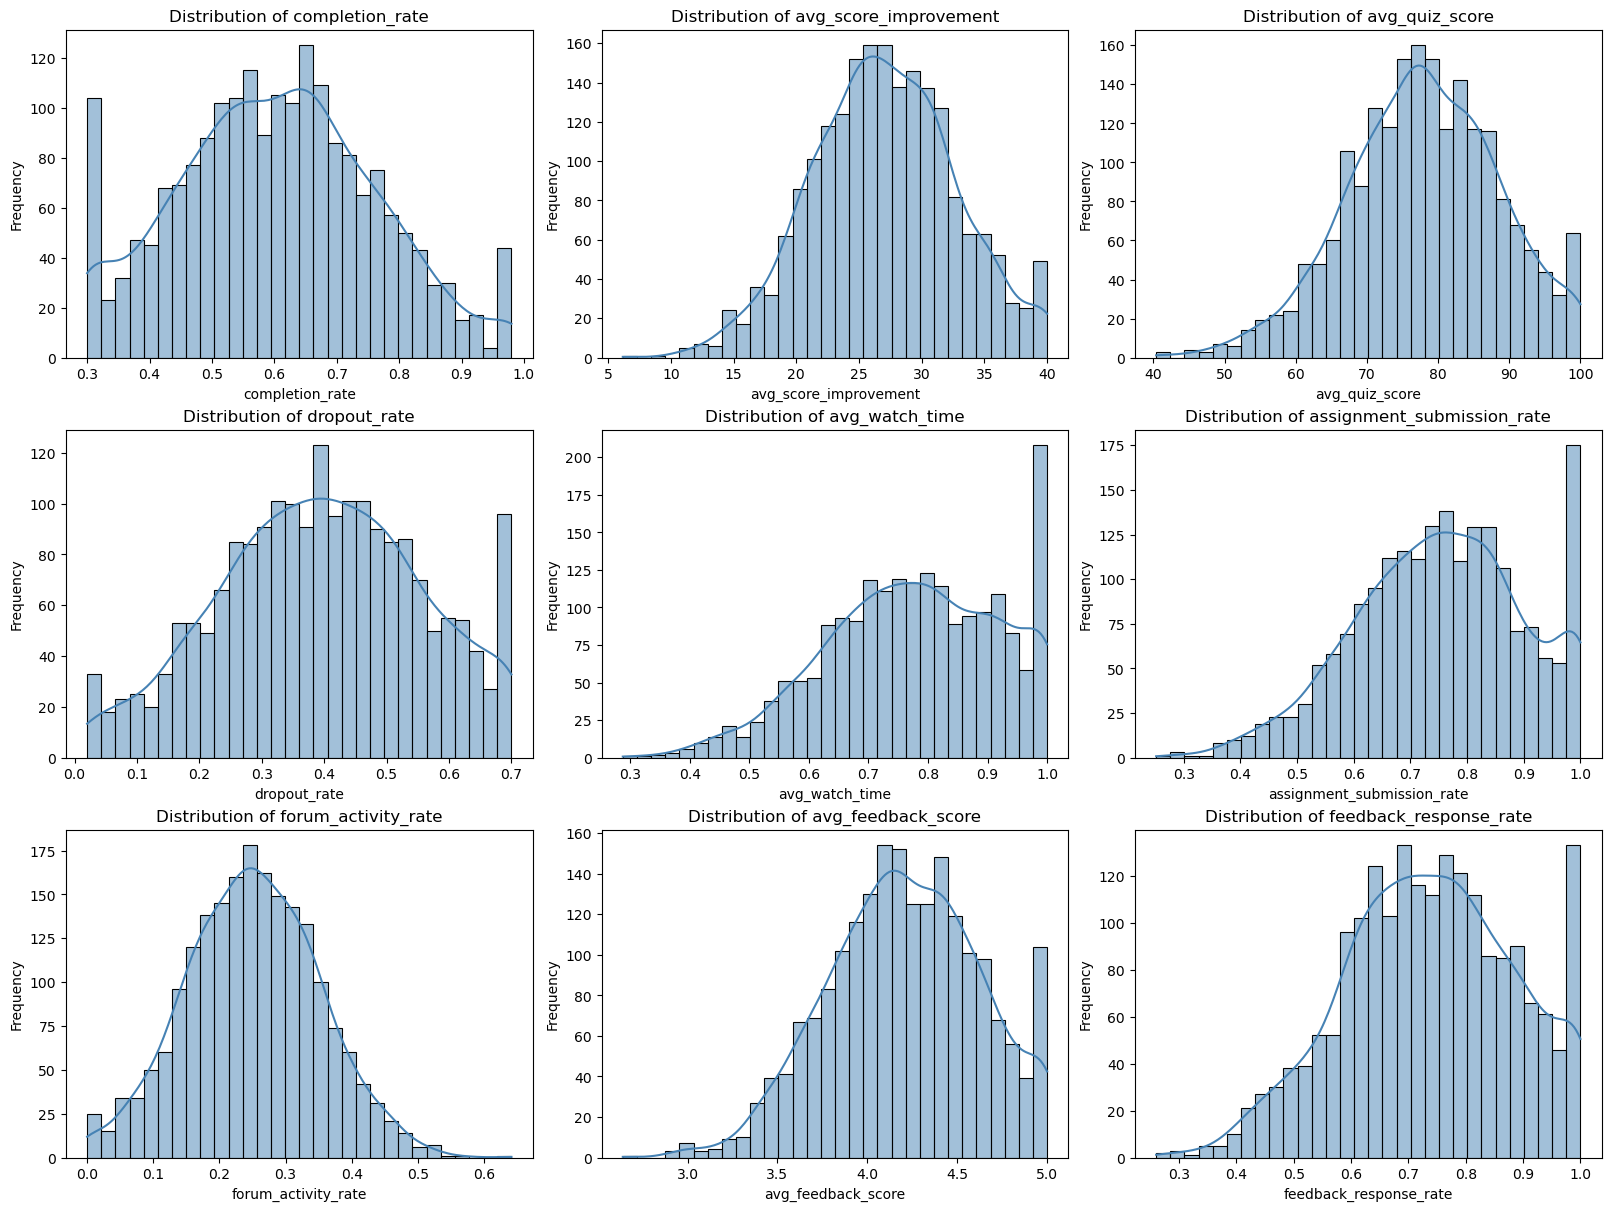

In [ ]:
# Histograms for numeric columns 

fig, axes = plt.subplots(3, 3, figsize = (16, 12), constrained_layout = True)
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(df[col], kde = True, bins = 30, ax = axes[i], color = 'steelblue')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel(col)
    axes[i].set_ylabel('Frequency')

plt.show()

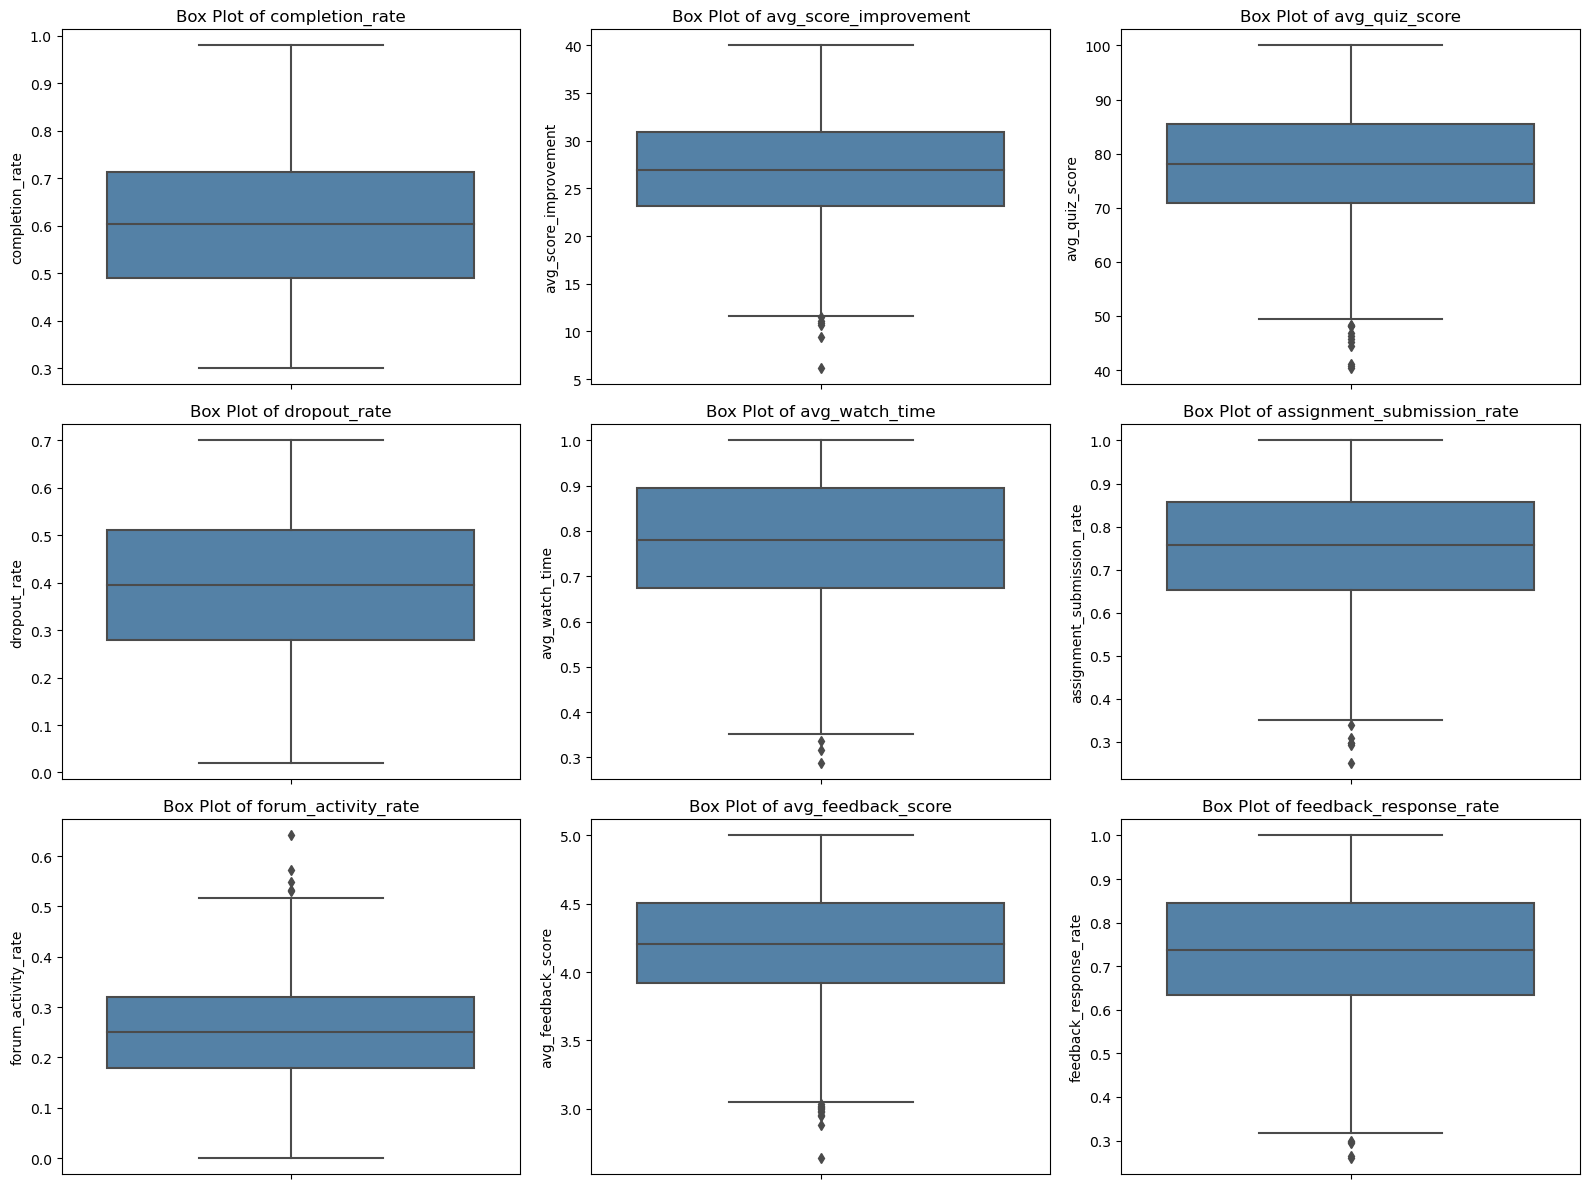

In [ ]:
# Box Plots 

fig, axes = plt.subplots(3, 3, figsize = (16, 12))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(y = df[col], ax = axes[i], color = 'steelblue')
    axes[i].set_title(f'Box Plot of {col}')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

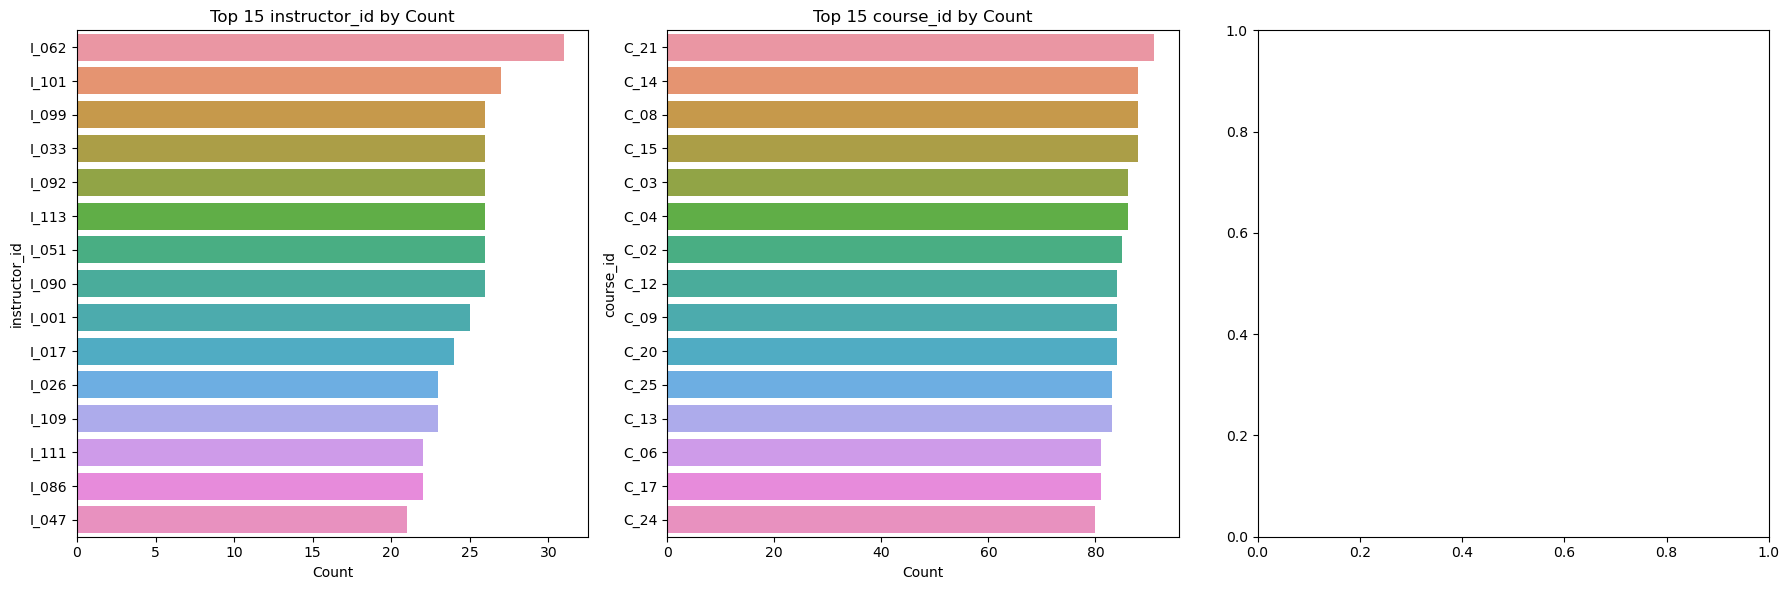

In [ ]:
# Count plots for categorical variables 

fig, axes = plt.subplots(1, 3, figsize = (18, 6))

for i, col in enumerate(categorical_cols):
    top_n = df[col].value_counts().head(15)
    sns.barplot(x = top_n.values, y = top_n.index, ax = axes[i])
    axes[i].set_title(f'Top 15 {col} by Count')
    axes[i].set_xlabel('Count')
    axes[i].set_ylabel(col)

plt.tight_layout()
plt.show()

In [22]:
df['instructor_id'].describe()

count      2000
unique      120
top       I_062
freq         31
Name: instructor_id, dtype: object

In [23]:
df['course_id'].describe()

count     2000
unique      25
top       C_21
freq        91
Name: course_id, dtype: object

Inferences 
- `completion_rate`: 0.3 is a hard floor (no data exists below it). 0.98 is hard ceiling (a perfect completion rate that appears suspiciously often). Else, the distribution is roughly normal around 0.6.
- `dropout_rate`: 0.02 is a hard floor (no data exists below it). 0.7 is hard ceiling. Else, the distribution is roughly normal around 0.4.
- `avg_score_improvement`: 40 is a hard ceiling. Most courses yield 20 - 35 score. 
- `avg_quiz_score`: 100 is a hard ceiling. Most courses average around 70 - 85 on quizes. 40 - 50 are low outliers. This is the strongest predictor of learning. 
- `avg_watch_time`: Most students watch ~75% of the course video indicating strong engagement. 
- `assingment_submission_rate`: Hard ceiling at 1. Median submission of 0.73 means ~ 27% of the assignments go unsubmitted.
- `forum_activity_rate`: No suspicious caps. 
- `avg_feedback_score`: Scores are compressed into the top of the 1-5 scale. 
- `feedback_response_rate`: Hard ceiling at 1. 

- `batch_id`: Each batch appears exactly once. One row - One batch. 2000 unique batches.
- `instructor_id`: 120 unique instructors. Top instructor teaches ~31 batches. 
- `course_id`: 25 unique courses. Top instructor has 85 batches. All courses have 70-85.

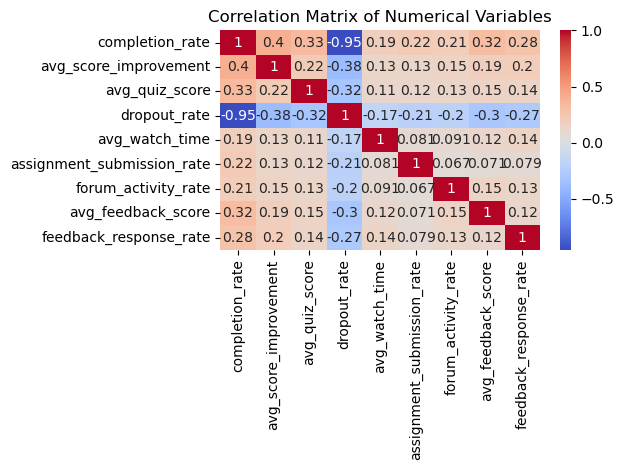

In [24]:
corr = df[numerical_cols].corr()

sns.heatmap(
    corr, annot = True, cmap = 'coolwarm'
)
plt.title('Correlation Matrix of Numerical Variables')
plt.tight_layout()
plt.show()

In [25]:
target_1 = 'completion_rate'
print(f'Correlations with {target_1}')
corr_with_target_1 = df[numerical_cols].corr()[target_1].drop(target_1).sort_values(key = abs, ascending=False)
print(corr_with_target_1.round(3))

print()

target_2 = 'avg_score_improvement'
print(f'Correlations with {target_2}')
corr_with_target_2 = df[numerical_cols].corr()[target_2].drop(target_2).sort_values(key = abs, ascending=False)
print(corr_with_target_2.round(3))

Correlations with completion_rate
dropout_rate                 -0.953
avg_score_improvement         0.404
avg_quiz_score                0.333
avg_feedback_score            0.315
feedback_response_rate        0.280
assignment_submission_rate    0.222
forum_activity_rate           0.206
avg_watch_time                0.188
Name: completion_rate, dtype: float64

Correlations with avg_score_improvement
completion_rate               0.404
dropout_rate                 -0.381
avg_quiz_score                0.219
feedback_response_rate        0.199
avg_feedback_score            0.190
forum_activity_rate           0.153
assignment_submission_rate    0.129
avg_watch_time                0.128
Name: avg_score_improvement, dtype: float64


Pairwise analysis


In [26]:
def get_pairs(df):
    cols = df.columns
    return list(combinations(cols, 2))

pairs = get_pairs(df)

In [27]:
def classify_pair(a, b, num_cols, cat_cols):
    a_num = a in num_cols
    b_num = b in num_cols
    
    if a_num and b_num:      
        return 'num-num'
    if not a_num and not b_num: 
        return 'cat-cat'
    return 'num-cat'

pair_info = [
    {'col_a': a, 'col_b': b, 'type': classify_pair(a, b, numerical_cols, categorical_cols)} for a, b in pairs
]
pair_df = pd.DataFrame(pair_info)
pair_df.head()

,col_a,col_b,type
0,instructor_id,course_id,cat-cat
1,instructor_id,completion_rate,num-cat
2,instructor_id,avg_score_improvement,num-cat
3,instructor_id,avg_quiz_score,num-cat
4,instructor_id,dropout_rate,num-cat


What to compute for each pair type
- num-num
    - Pearson r
    - Spearman p 
    - p-value
    - linear regression slope

-  num-cat
    - ANOVA F-stat
    - eta^2
    - group means 
    - Kruskal-Wallis

- cat-cat
    - Chi-square
    - Cramer's V
    - Contingency table

In [28]:
def analyze_numerical_numerical(df, a, b):
    x, y = df[a], df[b]
    common = df[[a, b]]
    x, y = common[a], common[b]

    pearson_r, pearson_p = stats.pearsonr(x, y)
    spearman_r, spearman_p = stats.spearmanr(x, y)

    slope, intercept, r_val, p_val, se = stats.linregress(x, y)

    return {
        'n': len(common),
        'pearson_r': round(pearson_r, 3),
        'pearson_p': pearson_p,
        'spearman_r': round(spearman_r, 3),
        'spearman_p': spearman_p,
        'r_squared': round(r_val**2, 3),
        'slope': round(slope, 4),
        'intercept': round(intercept, 4),
        'significant': pearson_p < 0.05,
    }

def analyze_numerical_categorical(df, num_col, cat_col):
    groups = [g[num_col].values for _, g in df.groupby(cat_col)]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) < 2:
        return None

    f_stat, anova_p = stats.f_oneway(*groups)
    h_stat, kw_p = stats.kruskal(*groups)

    # Eta-squared: effect size
    grand_mean = df[num_col].mean()
    ss_between = sum(len(g) * (g.mean() - grand_mean)**2 for g in groups)
    ss_total = ((df[num_col] - grand_mean)**2).sum()
    eta_sq = ss_between / ss_total if ss_total > 0 else 0

    return {
        'n_groups': len(groups),
        'anova_F': round(f_stat, 3),
        'anova_p': anova_p,
        'kruskal_H': round(h_stat, 3),
        'kruskal_p': kw_p,
        'eta_squared': round(eta_sq, 4),
        'significant': anova_p < 0.05,
        'group_means': {str(k): round(v, 3) for k, v in df.groupby(cat_col)[num_col].mean().items()},
    }

def analyze_categorical_categorical(df, a, b):
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, expected = stats.chi2_contingency(ct)

    n = ct.values.sum()
    min_dim = min(ct.shape) - 1
    cramers_v = np.sqrt(chi2 / (n * min_dim)) if min_dim > 0 else np.nan

    return {
        'table_shape': ct.shape,
        'chi2': round(chi2, 3),
        'p_value': p,
        'dof': dof,
        'cramers_v': round(cramers_v, 3),
        'significant': p < 0.05,
    }

In [29]:
results = []

for a, b in pairs:
    ptype = classify_pair(a, b, numerical_cols, categorical_cols)
    row = {'col_a': a, 'col_b': b, 'type': ptype}

    if ptype == 'num-num':
        row.update(analyze_numerical_numerical(df, a, b))
    elif ptype == 'num-cat':
        if a in categorical_cols:
            a, b = b, a
        r = analyze_numerical_categorical(df, a, b)
        if r: 
            row.update(r)
    elif ptype == 'cat-cat':
        row.update(analyze_categorical_categorical(df, a, b))
        
    results.append(row)

results_df = pd.DataFrame(results)

In [30]:
results_df[results_df['type'] == 'num-num'].dropna(axis = 1).head()

,col_a,col_b,type,significant,n,pearson_r,pearson_p,spearman_r,spearman_p,r_squared,slope,intercept
19,completion_rate,avg_score_improvement,num-num,True,2000.0,0.404,1.850298e-79,0.389,3.119156e-73,0.163,14.4704,18.3130
20,completion_rate,avg_quiz_score,num-num,True,2000.0,0.333,4.307915e-53,0.315,2.660365e-47,0.111,22.3273,64.4971
21,completion_rate,dropout_rate,num-num,True,2000.0,-0.953,0.000000e+00,-0.950,0.000000e+00,0.909,-0.9719,0.9807
22,completion_rate,avg_watch_time,num-num,True,2000.0,0.188,2.646047e-17,0.181,4.099735e-16,0.035,0.1707,0.6736
23,completion_rate,assignment_submission_rate,num-num,True,2000.0,0.222,9.977293e-24,0.210,2.554272e-21,0.049,0.2057,0.6292


In [31]:
results_df[results_df['type'] == 'num-cat'].dropna(axis = 1).head()

,col_a,col_b,type,significant,n_groups,anova_F,anova_p,kruskal_H,kruskal_p,eta_squared,group_means
1,instructor_id,completion_rate,num-cat,True,120.0,30.679,0.000000e+00,1262.704,2.569006e-190,0.6601,"{'I_001': 0.544, 'I_002': 0.731, 'I_003': 0.76..."
2,instructor_id,avg_score_improvement,num-cat,True,120.0,7.001,6.001838e-85,591.800,7.828889e-64,0.3071,"{'I_001': 26.641, 'I_002': 30.166, 'I_003': 29..."
3,instructor_id,avg_quiz_score,num-cat,True,120.0,4.281,2.592089e-42,403.461,1.289740e-32,0.2132,"{'I_001': 78.9, 'I_002': 81.737, 'I_003': 81.5..."
4,instructor_id,dropout_rate,num-cat,True,120.0,23.169,5.104736e-287,1137.761,7.913373e-166,0.5946,"{'I_001': 0.471, 'I_002': 0.247, 'I_003': 0.23..."
5,instructor_id,avg_watch_time,num-cat,True,120.0,2.010,2.688247e-09,224.082,1.934629e-08,0.1129,"{'I_001': 0.767, 'I_002': 0.837, 'I_003': 0.81..."


In [32]:
results_df[results_df['type'] == 'cat-cat'].dropna(axis = 1).head()

,col_a,col_b,type,table_shape,chi2,p_value,dof,cramers_v,significant
0,instructor_id,course_id,cat-cat,"(120, 25)",2847.076,0.543551,2856.0,0.244,False


Top num-num relationships (by |Pearson r|)

In [33]:
num_num = results_df[results_df['type'] == 'num-num'].copy()
num_num['abs_r'] = num_num['pearson_r'].abs()
num_num = num_num.sort_values('abs_r', ascending = False)

print('Top Numerical-Numerical Relationships')
print(num_num.head().dropna(axis = 1))

print()

num_cat = results_df[results_df['type'] == 'num-cat'].copy()
num_cat = num_cat.sort_values('eta_squared', ascending = False)

print('Top Numerical-Categorical Relationships')
print(num_cat.head().dropna(axis=1))

print()

cat_cat = results_df[results_df['type'] == 'cat-cat'].copy()

print('Top Categorical-Categorical Relationships')
print(cat_cat.head().dropna(axis=1))

Top Numerical-Numerical Relationships
                    col_a                  col_b     type  significant  \
21        completion_rate           dropout_rate  num-num         True   
19        completion_rate  avg_score_improvement  num-num         True   
28  avg_score_improvement           dropout_rate  num-num         True   
20        completion_rate         avg_quiz_score  num-num         True   
34         avg_quiz_score           dropout_rate  num-num         True   

         n  pearson_r     pearson_p  spearman_r    spearman_p  r_squared  \
21  2000.0     -0.953  0.000000e+00      -0.950  0.000000e+00      0.909   
19  2000.0      0.404  1.850298e-79       0.389  3.119156e-73      0.163   
28  2000.0     -0.381  3.051295e-70      -0.365  4.989631e-64      0.145   
20  2000.0      0.333  4.307915e-53       0.315  2.660365e-47      0.111   
34  2000.0     -0.315  2.217799e-47      -0.302  1.507018e-43      0.099   

      slope  intercept  abs_r  
21  -0.9719     0.9807  0.95

1. Numerical-Numerical 
    - `completion_rate` and `dropout_rate` are basically the same thing (r = -0.953). When one goes up, the other goes down almost perfectly. We will only keep one.
    - `completion_rate` and `avg_score_improvement` (r = 0.404) Students who improve more, complete more. 0.404^2 = 0.163 = 16.3%

    No single feature explains more than 16% of completion.

2. Numerical-Categorical
    - `instructor_id` and `completion_rate`: 66% of completion variance explained.
    - `course_id` and `instructor_id` didn't even make the top 5 meaning who teaches matters more than what is being taught
3. Categorical-Categorical
    - `instructor_id` and `course_id` (cramers_v = 0.244, p_value = 0.543) -> not significant. Instructors are randomly assigned to courses.

Anomaly

In [34]:
def detect_outliers_iqr(data, col):
    Q1 = data[col].quantile(0.25)
    Q3 = data[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = data[(data[col] < lower) | (data[col] > upper)]
    return len(outliers), lower, upper

outlier_summary = []
for col in numerical_cols:
    n_out, low, high = detect_outliers_iqr(df, col)
    outlier_summary.append({
        'Column': col,
        'Outlier Count': n_out,
        'Lower Bound': round(low, 3),
        'Upper Bound': round(high, 3)
    })

outlier_df = pd.DataFrame(outlier_summary)
outlier_df

,Column,Outlier Count,Lower Bound,Upper Bound
0,completion_rate,0,0.154,1.048
1,avg_score_improvement,6,11.483,42.527
2,avg_quiz_score,11,49.078,107.264
3,dropout_rate,0,-0.067,0.859
4,avg_watch_time,3,0.346,1.223
5,assignment_submission_rate,6,0.346,1.163
6,forum_activity_rate,5,-0.029,0.528
7,avg_feedback_score,11,3.042,5.380
8,feedback_response_rate,5,0.314,1.165


- `avg_quiz_score` and `avg_score_improvement` have the most outliers.
- `forum_activity_rate` has outliers only on the high side because lower bound is negative.
- `avg_feedback_score` outliers are almost all low because its upper bound exceeds the scale max of 5. 
- `completion_rate` and `dropout_rate` have almost no outliers. 

## Step 2 - Define Instructor Effectivenss Score

Index 

| # | Content Summary |
|---|---|
| 35 | `components`, PCA fit, `explained` scree table |
| 36 | PC1 sign check + flip |
| 37 | Extract IES weights `w` from PC1 |
| 38 | Computes `df['IES']` via MinMaxScaler |
| 39 | Creates `df['effectiveness_tier']` via `qcut(q=3)` |
| 40 | Prints tier summary (count, min, mean, max) |
| 41 | IES histogram + boxplot by tier |

**New columns in `df`:** `IES`, `effectiveness_tier`

**Key variables:** `components`, `w`, `weights`, `X_std`, `X_minmax`, `pca_full`, `scaler`, `pc1_scores`, `explained`

**Plots:** IES histogram with tertile cutoffs, IES boxplot by tier

IES: Instructor Effectiveness Score 

Design Principles
1. Outcome driven
2. Multi dimensional
3. Scale invariant 
4. Data justified 
5. Non-redundant - Exclude `dropout_rate` (r = -0.953 with `completion_rate`)
6. Directionally consistent 

In [35]:
components = [
    'completion_rate',
    'avg_score_improvement',
    'avg_quiz_score',
    'avg_feedback_score',
    'assignment_submission_rate',
    'avg_watch_time',
    'feedback_response_rate',
]

scaler = StandardScaler()
X_std = scaler.fit_transform(df[components])

pca_full = PCA(n_components = len(components), random_state = 1234)
pca_full.fit(X_std)

explained = pd.DataFrame({
    'PC': [f'PC{i+1}' for i in range(len(components))],
    'eig': pca_full.explained_variance_.round(3),
    'var_ratio': pca_full.explained_variance_ratio_.round(4),
    'cumulative': pca_full.explained_variance_ratio_.cumsum().round(4),
})

print("Scree table")
print(explained)

Scree table
    PC    eig  var_ratio  cumulative
0  PC1  2.148     0.3067      0.3067
1  PC2  0.945     0.1349      0.4416
2  PC3  0.923     0.1318      0.5735
3  PC4  0.875     0.1249      0.6984
4  PC5  0.830     0.1185      0.8169
5  PC6  0.759     0.1084      0.9253
6  PC7  0.523     0.0747      1.0000


- PC1 explains 30.67% of variance
- Cumulative:
    - PC1 + PC2 = 44.16%
    - PC1 + PC2 + PC3 = 57.35%
    - PC1 + PC2 + PC3 + PC4 + PC5 = 81.69%
    - PC1 + PC2 + PC3 + PC4 + PC5 + PC6 = 92.53%
    
    You need 5 PCs for 80% and 6 PC for 90% - meaning the 7 features are nearly orthogonal.

In [36]:
pc1_scores = X_std @ pca_full.components_[0]

checks = {
    'completion_rate':        df['completion_rate'],
    'avg_score_improvement':  df['avg_score_improvement'],
    'avg_quiz_score':         df['avg_quiz_score'],
}

print("Sign check — correlation of PC1 with outcome metrics:")
for name, col in checks.items():
    r = np.corrcoef(pc1_scores, col)[0, 1]
    print(f"  {name:25s}  r = {r:+.3f}")

# If most correlations are negative, flip PC1 sign 
if np.corrcoef(pc1_scores, df['completion_rate'])[0, 1] < 0:
    pca_full.components_[0] *= -1
    pc1_scores = -pc1_scores
    print("[sign flipped on PC1 so it points toward 'good']")


Sign check — correlation of PC1 with outcome metrics:
  completion_rate            r = -0.787
  avg_score_improvement      r = -0.641
  avg_quiz_score             r = -0.557
[sign flipped on PC1 so it points toward 'good']


- Before flip: PC1 correlates negatively with all three outcome metrics (-0.787, -0.641, -0.557)
- After flip: PC1 points towards good meaning high PC1 <-> high `completion_rate`, `avg_score_improvement`, `avg_quiz_score`.
- Strongest link is `completion_rate` (r = +0.787) -> PC1 will weight completion heaviest, matching the derived weights.

In [37]:
# IES weight extraction

w = np.abs(pca_full.components_[0])
w = w / w.sum()
weights = dict(zip(components, w))
weights

{'completion_rate': 0.20908213555237304,
 'avg_score_improvement': 0.17032408009610944,
 'avg_quiz_score': 0.1478891208679647,
 'avg_feedback_score': 0.1358071164599482,
 'assignment_submission_rate': 0.09945864516511249,
 'avg_watch_time': 0.10456741861251018,
 'feedback_response_rate': 0.13287148324598197}

| Feature | Weight | Category |
|---|---|---|
| completion_rate | 0.2091 | Outcome |
| avg_score_improvement | 0.1703 | Outcome |
| avg_quiz_score | 0.1479 | Outcome |
| avg_feedback_score | 0.1358 | Perception |
| feedback_response_rate | 0.1329 | Engagement |
| avg_watch_time | 0.1046 | Engagement |
| assignment_submission_rate | 0.0995 | Engagement |


- 53% of the score comes from outcomes `completion_rate` + `avg_score_improvement` + `avg_quiz_score` 
- 34% from engagement `feedback_response_rate` + `avg_watch_time` + `assignment_submission_rate`
- ~14% from perception 

$$\text{IES} = \sum_i w_i \cdot \tilde{x}_i, \quad \tilde{x}_i \in [0, 1]$$


In [ ]:
# IES Formula

X_minmax = MinMaxScaler().fit_transform(df[components])
df['IES'] = X_minmax @ w

- MinMaxScaler (not StandardScaler) is used for the final score because:
  1. It maps every feature into [0, 1] regardless of original scale.
  2. The weighted sum becomes interpretable as a "fraction of maximum effectiveness."
  3. Since all features are near-symmetric with thin tails, MinMax is not distorted by outliers.
- IES ∈ [0, 1], higher = more effective. Since weights sum to 1, an IES of 1 means a batch outperformed every other batch on every dimension.


In [39]:
# Tier Assignment 
df['effectiveness_tier'] = pd.qcut(
    df['IES'], q = 3, labels = ['Low', 'Medium', 'High']
)

`qcut(q = 3)` guarantees equal sized tiers (~667 batches each)

In [40]:
# tier summary
print(df.groupby('effectiveness_tier')['IES']
        .agg(['count','min','mean','max']).round(3))


                    count    min   mean    max
effectiveness_tier                            
Low                   667  0.183  0.481  0.553
Medium                666  0.553  0.608  0.657
High                  667  0.657  0.729  0.952


- Perfectly balanced tiers
- Low Tier (mean IES = 0.481): bottom third performers: weak on both outcomes and engagement.
- High Tier (mean IES = 0.729): top third performers: strong outcomes and, high engagement, positive feedback. Top batch reaches 0.952.
- Tier widths
    - Low: 0.553 - 0.183 = 0.37 (wide -> heterogeneous bottom)
    - Medium: 0.657 - 0.553 = 0.104 (narrow -> most batches cluster around the average)
    - High: 0.952 - 0.657 = 0.295 (wide -> heterogeneous top)
    
The narrow Medium Tier shows the score has a dense central peak with tails.

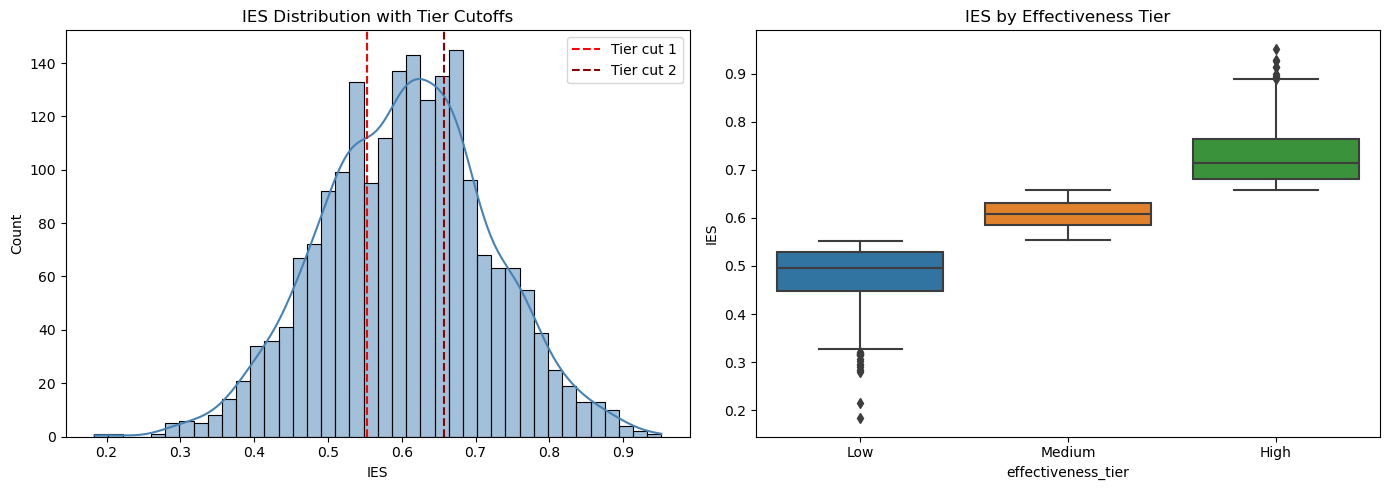

In [41]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df['IES'], bins=40, kde=True, color='steelblue', ax=axes[0])
axes[0].axvline(df['IES'].quantile(1/3), color='red',   linestyle='--', label='Tier cut 1')
axes[0].axvline(df['IES'].quantile(2/3), color='darkred', linestyle='--', label='Tier cut 2')
axes[0].set_title('IES Distribution with Tier Cutoffs')
axes[0].set_xlabel('IES')
axes[0].legend()

sns.boxplot(data=df, x='effectiveness_tier', y='IES',
            order=['Low','Medium','High'], ax=axes[1])
axes[1].set_title('IES by Effectiveness Tier')

plt.tight_layout()
plt.show()

- The IES histogram shows a bell-shaped distribution.
- Tertile cutoffs (red dashed lines) fall cleanly in the middle of the distribution - no tier is over or under populated.
- The box plots show and confirm clean tier separation

## Step 3 - Aggregate Batch Data to Instructor Level

Step 3

| # | Content Summary |
|---|---|
| 42 | Batch counts per instructor (`batch_counts`) |
| 43 | Aggregation → `instructor_df` (feature medians + IES stats + counts) |
| 44 | Evidence level assignment (`evidence_level` function) |
| 45 | Computes `instructor_df['IES_agg']` |
| 46 | Correlation between `IES_mean` and `IES_agg` |
| 47 | Creates `instructor_tier` + prints tier summary |
| 48 | Grouped `describe()` by instructor tier |
| 49 | Lists `instructor_df` columns |
| 50 | Scatter IES_mean vs IES_std + tier countplot |

**Functions defined:** `evidence_level`

**DataFrames created:** `instructor_df`, `batch_counts`

**New columns in `instructor_df`:** `IES_mean`, `IES_median`, `IES_std`, `n_batches`, `evidence`, `IES_agg`, `instructor_tier`

**Plots:** Scatter (IES_mean vs IES_std), Tier countplot

In [42]:
batch_counts = df.groupby('instructor_id').size()
print(batch_counts.describe())
print()
print("Instructors by batch count:")
print(batch_counts.value_counts().sort_index())

count    120.000000
mean      16.666667
std        4.582270
min        7.000000
25%       13.750000
50%       17.000000
75%       19.000000
max       31.000000
dtype: float64

Instructors by batch count:
7      1
8      4
9      1
10     5
11     5
12     4
13    10
14     7
15    10
16    12
17    13
18     8
19    14
20     7
21     5
22     2
23     2
24     1
25     1
26     6
27     1
31     1
Name: count, dtype: int64


In [43]:
# Aggregate batch -> instructor 

# how many batches per instructor 
n_batches = df.groupby('instructor_id').size().rename('n_batches')

# Numeric features: median across batches 
# not mean because median is robust to outliers unlike mean which is sensitive to outliers
feature_medians = (
    df.groupby('instructor_id')[components].median()
)

# IES 
ies_stats = df.groupby('instructor_id')['IES'].agg(
    IES_mean='mean',
    IES_median='median',
    IES_std='std'
)

instructor_df = feature_medians.join(ies_stats).join(n_batches).reset_index()

print(instructor_df.shape)
print(instructor_df.head())

(120, 12)
  instructor_id  completion_rate  avg_score_improvement  avg_quiz_score  \
0         I_001         0.545357              26.112106       78.961710   
1         I_002         0.723018              30.453036       77.930867   
2         I_003         0.754272              29.786063       83.114009   
3         I_004         0.431807              21.240292       75.573381   
4         I_005         0.871484              32.768176       86.624262   

   avg_feedback_score  assignment_submission_rate  avg_watch_time  \
0            4.249951                    0.738582        0.733658   
1            4.246529                    0.762905        0.853840   
2            4.429999                    0.757713        0.825693   
3            4.056810                    0.748872        0.785699   
4            4.223685                    0.864285        0.871003   

   feedback_response_rate  IES_mean  IES_median   IES_std  n_batches  
0                0.655761  0.575993    0.576560  0.07

The dataset collapses from 2000 batch rows to 120 instructor rows

In [44]:
def evidence_level(n):
    if n >= 10:
        return 'high'
    if n >= 3:
        return 'medium'
    return 'low'

instructor_df['evidence'] = instructor_df['n_batches'].apply(evidence_level)

print(instructor_df['evidence'].value_counts())

evidence
high      114
medium      6
Name: count, dtype: int64


- Output shows 114 instructors in high and 6 in medium, and no instructor in low. This means every instructor has at least 3 batches.

In [45]:
X_instr = MinMaxScaler().fit_transform(instructor_df[components])

instructor_df['IES_agg'] = X_instr @ w 

In [46]:
print(instructor_df[['IES_mean', 'IES_agg']].corr())


          IES_mean   IES_agg
IES_mean  1.000000  0.990771
IES_agg   0.990771  1.000000


Correlation = 0.990771. This is a strong validation that 
1. The PCA weights are stable across aggregation levels.
2. `IES_agg` (build from median features) and `IES_mean` (average of batch IES) agree.
3. The min-max rescaling at instructor level doesn't distort the ranking.

Since they're nearly identical, either can be used for tier assignment.

In [47]:
instructor_df['instructor_tier'] = pd.qcut(
    instructor_df['IES_agg'], q = 3, labels = ['Low', 'Medium', 'High']
)
print(instructor_df.groupby('instructor_tier')['IES_agg']
        .agg(['count', 'min', 'mean', 'max']).round(3))

                 count    min   mean    max
instructor_tier                            
Low                 40  0.040  0.311  0.421
Medium              40  0.424  0.486  0.555
High                40  0.555  0.663  0.920


In [48]:
instructor_df.groupby('instructor_tier')['IES_agg'].describe()

,count,mean,std,min,25%,50%,75%,max
instructor_tier,,,,,,,,
Low,40.0,0.310683,0.096749,0.039506,0.242295,0.342872,0.388581,0.420773
Medium,40.0,0.485977,0.041477,0.424436,0.448822,0.489982,0.525670,0.554871
High,40.0,0.662865,0.090889,0.555122,0.590242,0.647710,0.706847,0.920204


- Tiers are perfectly balanced.
- Low Tier: range 0.040-0.421, mean 0.310 - very wide spread (0.38) with the lowest score nearly at 0. This means some instructors are very weak.
- Medium Tier: range 0.424-0.555, mean 0.485 - width only 0.13, the narrowest band. Most instructors cluster tightly around the average.
- High Tier: range 0.555-0.920, mean 0.663 - width 0.37, also heterogenous.

The score is bell-shaped with a dense center and heavy tails. High-tier recognition should be reserved for the top handful (IES > 0.8), not all 40

In [49]:
print(instructor_df.columns.tolist())


['instructor_id', 'completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'avg_feedback_score', 'assignment_submission_rate', 'avg_watch_time', 'feedback_response_rate', 'IES_mean', 'IES_median', 'IES_std', 'n_batches', 'evidence', 'IES_agg', 'instructor_tier']


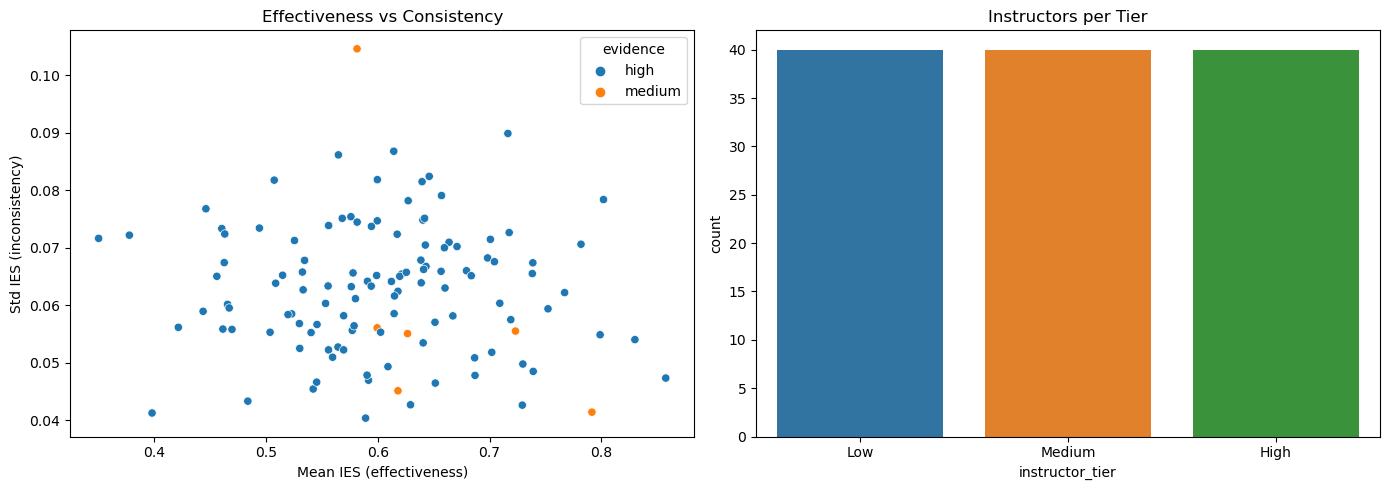

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: consistency vs effectiveness
sns.scatterplot(data=instructor_df, x='IES_mean', y='IES_std',
                hue='evidence', ax=axes[0])
axes[0].set_title('Effectiveness vs Consistency')
axes[0].set_xlabel('Mean IES (effectiveness)')
axes[0].set_ylabel('Std IES (inconsistency)')

# Tier distribution
sns.countplot(data=instructor_df, x='instructor_tier',
              order=['Low','Medium','High'], ax=axes[1])
axes[1].set_title('Instructors per Tier')

plt.tight_layout()
plt.show()

- No clear trend between `IES_mean` and `IES_std`. This means consistency is an independent dimension, not a by-product of effectiveness. Two instructors can have identical `IES_mean` but different `IES_std`

## Step 4 - Build a Machine Learning Model

Index 

| # | Content Summary |
|---|---|
| 51 | Defines `features`, `X`, `y`, LabelEncoder, train/test split, scaling |
| 52 | Trains 4 models: `log_reg`, `rf`, `gb`, `xgb` + predictions |
| 53 | Prints accuracy + classification report for all 4 models |
| 54 | RF feature importance bar plot → `feature_importance_df` |

**Models trained:** `log_reg`, `rf`, `gb`, `xgb`

**Predictions:** `y_pred_lr`, `y_pred_rf`, `y_pred_gb`, `y_pred_xgb`

**Key variables:** `X`, `y`, `X_train`, `X_test`, `y_train`, `y_test`, `X_train_scaled`, `X_test_scaled`, `le`, `label_map`, `models`

**Plots:** RF feature importance bar plot

In [51]:
# X will contain the features
features = components 
X = instructor_df[features]
y = instructor_df['instructor_tier']

print("Shape of features:", X.shape)
print("Feature columns:", X.columns.tolist())

# Encode target 
le = LabelEncoder()
y = le.fit_transform(instructor_df['instructor_tier'])
label_map = dict(zip(le.classes_, le.transform(le.classes_)))
print("\nLabel encoding:", label_map)   # {'High': 0, 'Low': 1, 'Medium': 2}

# split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=1234, stratify=y
)
print("\nTraining set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

# Scale the numerical features 
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


Shape of features: (120, 7)
Feature columns: ['completion_rate', 'avg_score_improvement', 'avg_quiz_score', 'avg_feedback_score', 'assignment_submission_rate', 'avg_watch_time', 'feedback_response_rate']

Label encoding: {'High': 0, 'Low': 1, 'Medium': 2}

Training set shape: (84, 7)
Testing set shape: (36, 7)


In [52]:
# 1. Logistic Regression
log_reg = LogisticRegression(max_iter=1000, random_state=1234)
log_reg.fit(X_train_scaled, y_train)
y_pred_lr = log_reg.predict(X_test_scaled)

# 2. Random Forest Classifier
rf = RandomForestClassifier(n_estimators=100, random_state=1234, oob_score=True)
rf.fit(X_train, y_train) # Random Forest doesn't need scaled data
y_pred_rf = rf.predict(X_test)

# 3. Gradient Boosting Classifier 
gb = GradientBoostingClassifier(n_estimators=100, random_state=1234)
gb.fit(X_train, y_train) # Gradient Boosting doesn't need scaled data
y_pred_gb = gb.predict(X_test)

# 4. XGBoost 
xgb = XGBClassifier(
    n_estimators = 100,
    learning_rate = 0.1,
    max_depth = 4,
    random_state = 1234,
    eval_metric = 'mlogloss',
)
xgb.fit(X_train, y_train)
y_pred_xgb = xgb.predict(X_test)

In [53]:
models = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb
}

for name, predictions in models.items():
    print(f"\n{name}")
    print(f"Accuracy: {accuracy_score(y_test, predictions):.4f}")
    print("Classification Report:")
    print(classification_report(y_test, predictions, target_names=['High', 'Low', 'Medium']))



Logistic Regression
Accuracy: 0.9722
Classification Report:
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        12
         Low       1.00      0.92      0.96        12
      Medium       0.92      1.00      0.96        12

    accuracy                           0.97        36
   macro avg       0.97      0.97      0.97        36
weighted avg       0.97      0.97      0.97        36


Random Forest
Accuracy: 0.8056
Classification Report:
              precision    recall  f1-score   support

        High       1.00      0.75      0.86        12
         Low       0.79      0.92      0.85        12
      Medium       0.69      0.75      0.72        12

    accuracy                           0.81        36
   macro avg       0.83      0.81      0.81        36
weighted avg       0.83      0.81      0.81        36


Gradient Boosting
Accuracy: 0.7778
Classification Report:
              precision    recall  f1-score   support

        

- Logistic Regression dominates - 97.2% accuracy means it misclassifies only 1 out of 36 instructors.
- The classes are linearly separable - a linear model beating all tree-based ensembles strongly implies a linear decision boundary. 
- Medium tier is hardest across every model. All four models produce their lowest F1 on Medium (0.64 - 0.96). 
- XGBoost and Gradient Boosting are tied at 77.8% - boosting offers no advantage over this small dataset.
- High precision on all models for High tier (>= 0.82) means when the model says High, it is almost always right.

                      feature  importance
0             completion_rate    0.279508
1       avg_score_improvement    0.179620
3          avg_feedback_score    0.168726
2              avg_quiz_score    0.166651
6      feedback_response_rate    0.087525
5              avg_watch_time    0.067890
4  assignment_submission_rate    0.050081


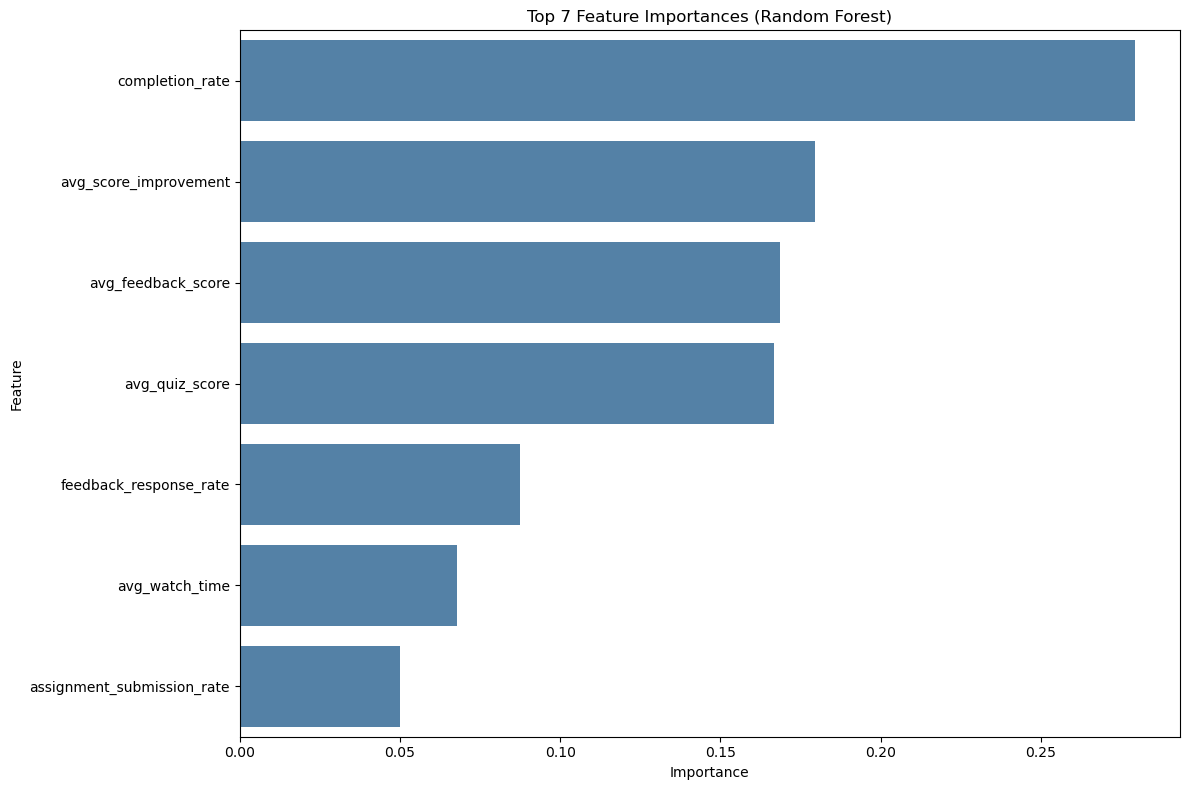

In [54]:
# feature importance analysis 
importances = rf.feature_importances_

feature_importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': importances
})

# Sort by importance and show the top 7
feature_importance_df = feature_importance_df.sort_values(by='importance', ascending=False).head(7)
print(feature_importance_df)

# Plot the feature importances
plt.figure(figsize=(12, 8))
sns.barplot(x='importance', y='feature', data=feature_importance_df, color='steelblue')
plt.title('Top 7 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

- Outcome features dominate - `completion_rate`, `avg_score_improvement` and `avg_quiz_score` are at the top. This aligns with the PCA-derived IES weights, where these three together carry ~53% of the total weight.
- Engagement features act as tiebreakers - `assignment_submission_rate`, `avg_watch_time` and `feedback_response_rate` contribute less individually. They matter most when separating the Medium tier from its neighbours. 
- `avg_feedback_score` is mid-tier in importance - perception is informative but weaker than the direct outcome metrics.

## Step 5 - Evaluating the Model

Index  

| # | Content Summary |
|---|---|
| 55 | Train/test class distribution → `dist_df` |
| 56 | Confusion matrices (2×2) for all 4 models |
| 57 | `metrics_df` — Accuracy, Precision, Recall, F1 per model |
| 58 | Precision vs Recall bar chart → `pr_df` |
| 59 | Confidence distribution → `conf_df` |
| 60 | Mean / median / min confidence |

**DataFrames created:** `dist_df`, `metrics_df`, `pr_df`, `conf_df`

**Plots:** Confusion matrices (2×2), Precision vs Recall bar chart

**Key variables:** `model_preds`, `class_names`, `proba`, `max_proba`, `prec`, `rec`, `f1`, `sup`, `train_dist`, `test_dist`

In [55]:
train_dist = pd.Series(y_train).value_counts().sort_index()
test_dist = pd.Series(y_test).value_counts().sort_index()

label_lookup = {v: k for k, v in label_map.items()}

dist_df = pd.DataFrame({
    'Train Count': train_dist,
    'Train %': (train_dist / train_dist.sum() * 100).round(2),
    'Test Count': test_dist,
    'Test %': (test_dist / test_dist.sum() * 100).round(2),
})

dist_df.index = [label_lookup[i] for i in dist_df.index]
dist_df

,Train Count,Train %,Test Count,Test %
High,28,33.33,12,33.33
Low,28,33.33,12,33.33
Medium,28,33.33,12,33.33


- Train and test sets both contain 12 samples per class 
- Original distribution: 40/ 40/ 40 instructors across Low/ Medium/ High

There is no class imbalance.

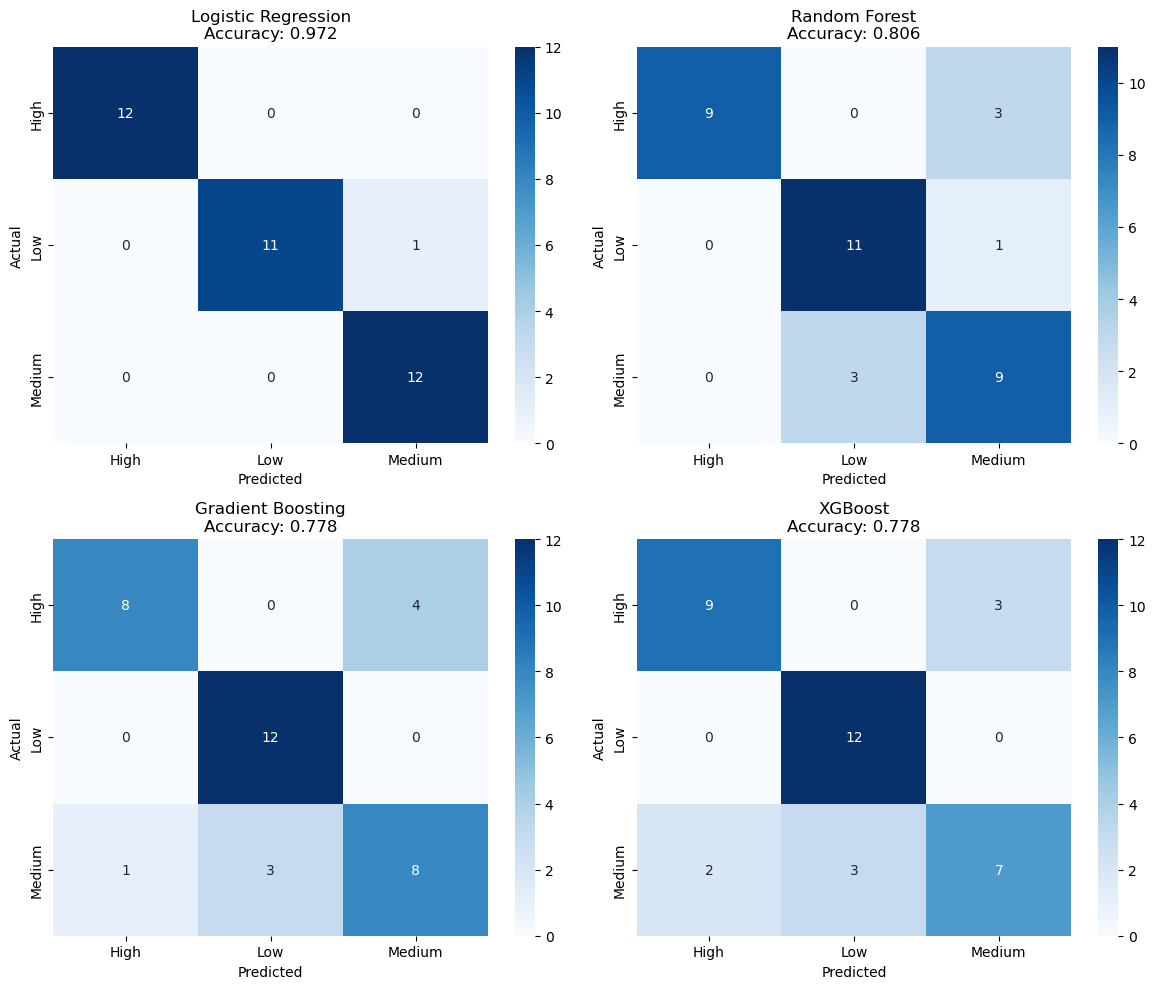

In [56]:
# Confusion matrices for all four models

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

model_preds = {
    "Logistic Regression": y_pred_lr,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "XGBoost": y_pred_xgb,
}

class_names = ['High', 'Low', 'Medium']

for ax, (name, preds) in zip(axes, model_preds.items()):
    cm = confusion_matrix(y_test, preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'{name}\nAccuracy: {accuracy_score(y_test, preds):.3f}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

- Logistic Regression (best model)
    - 1 error total out of 36 predictions
    - There is only one mistake - 1 Low Tier instructor was predicted Medium
    - Zero mistakes on High and Medium classes.

- Random Forest 
    - Error: Medium <-> Low confusion
    - 3 High Tier instructors were predicted as Medium.
    - No High/ Mid instructor was ever predicted as Low 

- Gradient Boosting and XGBoost
    - Both models over predict Low - this is why their recall was 1.00 on Low but weak precision on Medium.
    - Medium was frequently misclassified as Low.

    

In [57]:
metrics_list = []
for name, preds in model_preds.items():
    metrics_list.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, preds),
        'Macro Precision': precision_score(y_test, preds, average='macro'),
        'Macro Recall': recall_score(y_test, preds, average='macro'),
        'Macro F1': f1_score(y_test, preds, average='macro'),
        'Weighted F1': f1_score(y_test, preds, average='weighted'),
    })

metrics_df = pd.DataFrame(metrics_list).set_index('Model').round(4)
metrics_df = metrics_df.sort_values('Accuracy', ascending=False)
metrics_df


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
Model,,,,,
Logistic Regression,0.9722,0.9744,0.9722,0.9722,0.9722
Random Forest,0.8056,0.8260,0.8056,0.8078,0.8078
Gradient Boosting,0.7778,0.7852,0.7778,0.7725,0.7725
XGBoost,0.7778,0.7727,0.7778,0.7693,0.7693


- Accuracy - Overall correctness: Classes are balanced, so accuracy is not misleading.
- Macro Precision - How often predictions for a class are correct, averaged equally
- Macro Recall - How often a class is captured, averaged equally
- Macro F1 - Harmonic Mean of precision and recall
- Weighted F1 - F1 weighted by class support

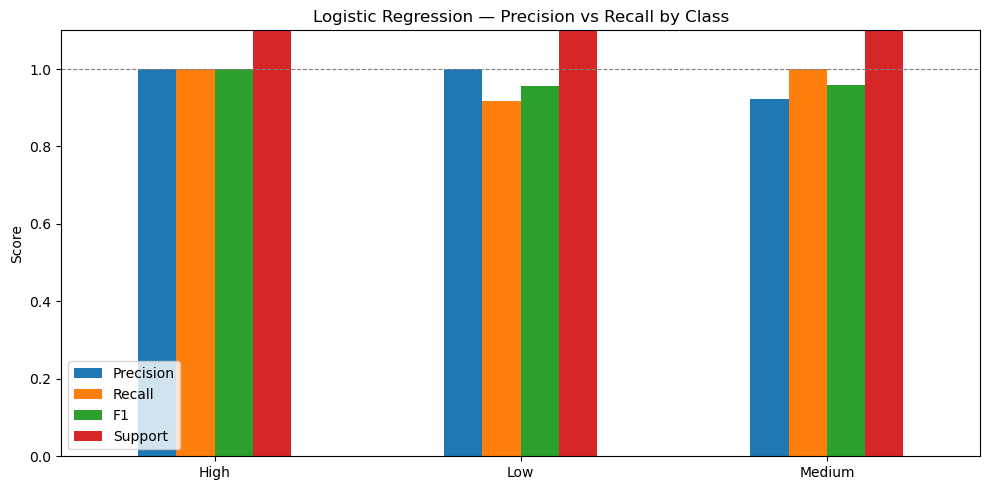

,Precision,Recall,F1,Support
High,1.000,1.000,1.000,12
Low,1.000,0.917,0.957,12
Medium,0.923,1.000,0.960,12


In [58]:
# Precision vs Recall heatmap for the best model
from sklearn.metrics import precision_recall_fscore_support

prec, rec, f1, sup = precision_recall_fscore_support(
    y_test, y_pred_lr, labels=[0, 1, 2]
)

pr_df = pd.DataFrame({
    'Precision': prec,
    'Recall': rec,
    'F1': f1,
    'Support': sup,
}, index=['High', 'Low', 'Medium']).round(3)

pr_df.plot(kind='bar', figsize=(10, 5), rot=0,
           title='Logistic Regression — Precision vs Recall by Class')
plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.axhline(1.0, color='gray', linestyle='--', linewidth=0.8)
plt.tight_layout()
plt.show()

pr_df

- High tier is perfect - if the model says High, it is High
- Low Tier has a small recall gap (precision - recall : 0.83) - One Low instructor was missed as Medium.
- Medium Tier has a small precision gap (0.77) - The model occasionally predicts Medium for samples that are actually low.

In [59]:
# Prediction confidence on the test set

proba = log_reg.predict_proba(X_test_scaled)
max_proba = proba.max(axis=1)

conf_df = pd.DataFrame({
    'True Label': [label_lookup[y] for y in y_test],
    'Predicted': [label_lookup[y] for y in y_pred_lr],
    'Confidence': max_proba.round(3),
    'Correct': y_test == y_pred_lr,
}).sort_values('Confidence')

print("Confidence distribution summary:")
print(conf_df['Confidence'].describe().round(3))
print("\nLowest-confidence predictions:")
print(conf_df.head(5).to_string(index=False))

Confidence distribution summary:
count    36.000
mean      0.799
std       0.176
min       0.502
25%       0.646
50%       0.799
75%       0.980
max       1.000
Name: Confidence, dtype: float64

Lowest-confidence predictions:
True Label Predicted  Confidence  Correct
    Medium    Medium       0.502     True
    Medium    Medium       0.532     True
    Medium    Medium       0.545     True
      High      High       0.551     True
       Low       Low       0.554     True


In [60]:
proba = log_reg.predict_proba(X_test_scaled)
max_proba = proba.max(axis=1)
print("Mean confidence:", max_proba.mean())
print("Median confidence:", np.median(max_proba))
print("Min confidence:", max_proba.min())

Mean confidence: 0.7987482846347685
Median confidence: 0.7990410498135848
Min confidence: 0.50189973302991


The model is correct but under confident. This is common for multinomial Logistic Regression on small samples.

## Step 6 - Interpret the Results

Index

| # | Content Summary |
|---|---|
| 61 | `importance_all` — feature importances across all 4 models |
| 62 | `perm_df` — permutation importances on test set |
| 63 | `coef_df` — Logistic Regression coefficients per class |
| 64 | `tier_profile` — mean feature values per instructor tier |
| 65 | Tier profile heatmap (Z-scored) |
| 66 | `examples` — top 2 High + bottom 2 Low instructors |

**DataFrames created:** `importance_all`, `perm_df`, `coef_df`, `tier_profile`, `tier_profile_std`, `examples`

**Plots:** Tier profile heatmap (Z-scored)

**Key variables:** `rf_imp`, `gb_imp`, `xgb_imp`, `lr_imp`, `perm_result`, `lr_coefs`, `example_high`, `example_low`

In [61]:
# Compare feature importances across all models

# Random Forest importances
rf_imp = pd.Series(rf.feature_importances_, index=X.columns, name='Random Forest')

# Gradient Boosting importances
gb_imp = pd.Series(gb.feature_importances_, index=X.columns, name='Gradient Boosting')

# XGBoost importances
xgb_imp = pd.Series(xgb.feature_importances_, index=X.columns, name='XGBoost')

# Logistic Regression - use absolute coefficients, averaged over classes
lr_coefs = np.abs(log_reg.coef_).mean(axis=0)
lr_imp = pd.Series(lr_coefs / lr_coefs.sum(), index=X.columns, name='Logistic Regression')

# Combine into one DataFrame
importance_all = pd.concat([lr_imp, rf_imp, gb_imp, xgb_imp], axis=1)
importance_all['Average'] = importance_all.mean(axis=1)
importance_all = importance_all.sort_values('Average', ascending=False).round(4)

importance_all

,Logistic Regression,Random Forest,Gradient Boosting,XGBoost,Average
completion_rate,0.1794,0.2795,0.6323,0.4596,0.3877
avg_quiz_score,0.1643,0.1667,0.2309,0.2545,0.2041
avg_feedback_score,0.1793,0.1687,0.0363,0.1047,0.1222
avg_score_improvement,0.1697,0.1796,0.0046,0.0409,0.0987
feedback_response_rate,0.1001,0.0875,0.0336,0.0761,0.0743
avg_watch_time,0.1309,0.0679,0.0204,0.0274,0.0617
assignment_submission_rate,0.0763,0.0501,0.0419,0.0367,0.0513


- Four models, for different algorithms yet the same features are at the top.
- Confirms PCA weights - The top 3 features here are also te top 3 by PCA weight in IES.
- `completion_rate` dominates every model
- `avg_quiz_score` is consistently at 2nd positio  across all models.
- Engagement features are at the bottom across every model.
- `avg_feedback_score` beats the engagement features.

In [62]:
# Permutation importance on the test set

perm_result = permutation_importance(
    log_reg, X_test_scaled, y_test,
    n_repeats=30, random_state=1234, scoring='accuracy'
)

perm_df = pd.DataFrame({
    'Feature': X.columns,
    'Mean Drop in Accuracy': perm_result.importances_mean.round(4),
    'Std': perm_result.importances_std.round(4),
}).sort_values('Mean Drop in Accuracy', ascending=False)

perm_df

,Feature,Mean Drop in Accuracy,Std
2,avg_quiz_score,0.2056,0.0333
3,avg_feedback_score,0.2046,0.0409
5,avg_watch_time,0.1713,0.0443
0,completion_rate,0.1620,0.0542
6,feedback_response_rate,0.1546,0.0326
1,avg_score_improvement,0.1463,0.0555
4,assignment_submission_rate,0.0935,0.0484


| Feature | Training Rank | Permutation Rank |
|---|---|---|
| completion_rate | 1 | 4 |
| avg_quiz_score | 2 | 1|
| avg_feedback_score | 3 | 2 |
| avg_score_improvement | 4 | 6 |
| avg_watch_time | 6 | 3 |
| feedback_response_rate | 5 | 5 |
| assignment_submission_rate | 7 | 7 |


- Training importances tells how the model uses each feature. Permutation importances tells how much the model relies on each feature for accurate prediction.
- Top performers cluster tightly (0.20 +- 0.05)
- `assignment_submission_rate` is nearly redundant.
- The model isn't a 'single-feature classifier'. It is multi-dimensional - dropping any one feature costs 9-21% accuracy. This validates the multi-dimensional IES design
- All mean drops are positive - every feature contributes positively. No feature is actively harmful.

In [ ]:
# Logistic Regression coefficients per class

coef_df = pd.DataFrame(
    log_reg.coef_.T,
    index=X.columns,
    columns=['High', 'Low', 'Medium']  # matches LabelEncoder order
).round(3)

coef_df['Interpretation'] = coef_df.apply(
    lambda row: f"Most positive -> {row.idxmax()}",
    axis=1
)

coef_df

,High,Low,Medium,Interpretation
completion_rate,0.929,-1.363,0.434,Most positive -> High
avg_score_improvement,0.877,-1.289,0.412,Most positive -> High
avg_quiz_score,1.248,-0.978,-0.270,Most positive -> High
avg_feedback_score,1.362,-1.127,-0.235,Most positive -> High
assignment_submission_rate,0.523,-0.579,0.057,Most positive -> High
avg_watch_time,0.994,-0.740,-0.254,Most positive -> High
feedback_response_rate,0.760,-0.723,-0.037,Most positive -> High


- Every single feature has its most positive coefficient pointing toward High. This points out that the IES's 'directionally consistent' design principle is respected.
- `avg_feedback_score` is the strongest discriminator of High (1.362). 
- `completion_rate` is the strongest discriminator of Low (-1.363).
- `assignment_submission_rate` is the weakest signal (High = 0.523, Low = -0.579, Medium = 0.057). It barely helps distinguish any class.

In [67]:
# Average feature values per instructor tier

tier_profile = instructor_df.groupby('instructor_tier')[components].mean().round(3)
tier_profile.index = tier_profile.index.astype(str)
tier_profile.T

instructor_tier,Low,Medium,High
completion_rate,0.453,0.609,0.738
avg_score_improvement,23.550,27.620,29.931
avg_quiz_score,73.320,77.500,83.256
avg_feedback_score,4.030,4.192,4.397
assignment_submission_rate,0.708,0.759,0.802
avg_watch_time,0.738,0.774,0.836
feedback_response_rate,0.677,0.732,0.803



|Feature |Low -> Med	|  Med -> High |	Total Gap |
|---|---|---|---|
|completion_rate |	+0.156 |	+0.129	|+0.285|
|avg_score_improvement|	+4.07	|+2.31	|+6.38|
|avg_quiz_score	|+4.18	|+5.76	|+9.94|
|avg_feedback_score	|+0.162	|+0.205	|+0.367|
|assignment_submission_rate	|+0.051	|+0.043|+0.094|
|avg_watch_time	|+0.036	|+0.062	|+0.098|
|feedback_response_rate	|+0.055	|+0.071	|+0.126|

- `avg_quiz_score` has the largest total gap (9.94 points) making it the strongest physical separator between tiers.
- `assignment_submission_rate` has the smallest gap (0.094) making it the weakest tier discriminator.
- `Low -> Medium` gap is larger than `Medium -> High` on outcome features meaning 
    - the biggest quality jump is coming out of the Low tier
    - Moving from Medium to High requires smaller but more consistent improvements.
- `Medium -> High` gap is larger on engagement features (`avg_quiz_score`: 5.76 vs 4.18; `avg_feedback_score`: 0.205 vs 0.162; `avg_watch_time`: 0.062 vs 0.036) meaning 
    - Getting to Medium is about fixing the fundamentals (completion, improvement)
    - Getting to High requires deepening engagement (quiz mastery, feedback quality, watch time)

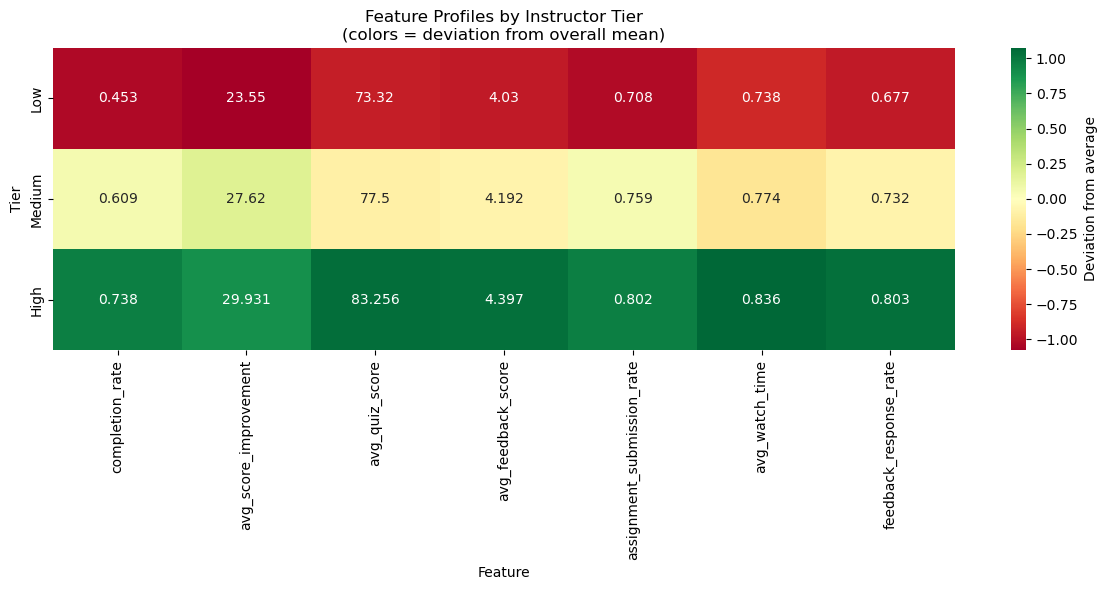

In [65]:
# Visualise tier profiles

tier_profile_std = (tier_profile - tier_profile.mean()) / tier_profile.std()

plt.figure(figsize=(12, 6))
sns.heatmap(tier_profile_std, annot=tier_profile.values,
            fmt='', cmap='RdYlGn', center=0,
            cbar_kws={'label': 'Deviation from average'})
plt.title('Feature Profiles by Instructor Tier\n(colors = deviation from overall mean)')
plt.xlabel('Feature')
plt.ylabel('Tier')
plt.tight_layout()
plt.show()

In [66]:
# Concrete examples from each tier
example_high = instructor_df[instructor_df['instructor_tier'] == 'High'].nlargest(2, 'IES_agg')
example_low  = instructor_df[instructor_df['instructor_tier'] == 'Low'].nsmallest(2, 'IES_agg')

examples = pd.concat([example_high, example_low])[
    ['instructor_id', 'instructor_tier', 'IES_agg', 'n_batches'] + components
]
examples.round(3)

,instructor_id,instructor_tier,IES_agg,n_batches,completion_rate,avg_score_improvement,avg_quiz_score,avg_feedback_score,assignment_submission_rate,avg_watch_time,feedback_response_rate
9,I_010,High,0.920,13,0.980,35.647,89.798,4.518,0.830,0.930,0.912
36,I_037,High,0.838,15,0.914,35.066,84.777,4.472,0.808,0.944,0.846
43,I_044,Low,0.040,15,0.300,18.364,65.287,3.766,0.571,0.695,0.542
74,I_075,Low,0.084,19,0.300,19.578,63.979,3.798,0.665,0.656,0.620
